# Forest Fire Detection using a Convolutional Neural Network

**Problem statement:** Wildfires spread quickly, and early detection greatly reduces the damage to forests, wildlife and human settlements. Manual monitoring of camera and satellite imagery is slow and error-prone. This project builds a CNN that classifies an image as **Fire** or **No Fire**, which could support automated early-warning systems.

**Dataset:** FIRE Dataset (Kaggle, `phylake1337/fire-dataset`, CC0 licence), containing 999 labelled images in two classes: fire and non-fire.

**Pipeline:** Setup → Dataset exploration → Preprocessing → Augmentation → Model → Training → Evaluation

## 1. Setup

In this section we install the required libraries and import the tools used throughout the project:
- **TensorFlow / Keras** to build and train the CNN
- **scikit-learn** for the train/test split, class weights and evaluation metrics
- **Matplotlib / Seaborn** for visualisation

Random seeds are fixed for NumPy and TensorFlow (`42`) so that the data split and results are as reproducible as possible. The GPU check confirms that training will run on a GPU, which speeds up CNN training considerably.

In [1]:
!pip install -q kaggle scikit-learn seaborn

import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                              precision_score, recall_score, f1_score,
                              roc_curve, auc, accuracy_score)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))
tf.random.set_seed(42)
np.random.seed(42)


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Dataset

We use the **FIRE Dataset** from Kaggle, downloaded through the Kaggle API. It contains two folders:
- `fire_images`: images containing fire
- `non_fire_images`: images without fire

The dataset is released under the CC0 (public domain) licence, so it can be used freely for academic work.

In [2]:
# Download the FIRE Dataset
!kaggle datasets download -d phylake1337/fire-dataset -p /content/data --unzip

DATA_DIR = "/content/data/fire_dataset"
print(os.listdir(DATA_DIR))

Dataset URL: https://www.kaggle.com/datasets/phylake1337/fire-dataset
License(s): CC0-1.0
100% 387M/387M [00:22<00:00, 17.8MB/s]

['fire_images', 'non_fire_images']


## 3. Dataset Exploration

Before any processing, we check the size and balance of the dataset and look at some sample images.

**Observations:**
- The dataset has 999 images: 755 fire (75.6%) and 244 non-fire (24.4%).
- The classes are **imbalanced** (about 3 : 1). A model that always predicts "fire" would already reach about 75% accuracy, so accuracy alone is misleading. We therefore also report precision, recall, F1 and ROC-AUC, and we handle the imbalance with class weights during training.
- The sample images below show the visual variety within each class (different scenes, lighting and fire sizes), which the model must learn to handle.

In [9]:
fire_dir = os.path.join(DATA_DIR, "fire_images")
non_fire_dir = os.path.join(DATA_DIR, "non_fire_images")

fire_files = [f for f in os.listdir(fire_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
non_fire_files = [f for f in os.listdir(non_fire_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]

print(f"Fire images:      {len(fire_files)}")
print(f"Non-fire images:  {len(non_fire_files)}")
print(f"Total images:     {len(fire_files) + len(non_fire_files)}")
print(f"Class imbalance:  {len(fire_files) / (len(fire_files) + len(non_fire_files)) * 100:.1f}% fire")

Fire images:      755
Non-fire images:  244
Total images:     999
Class imbalance:  75.6% fire


Class distribution plot

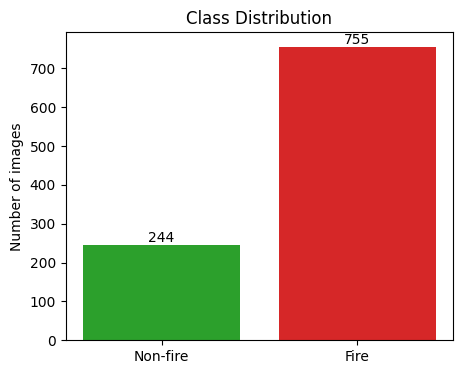

In [10]:
counts = [len(non_fire_files), len(fire_files)]
plt.figure(figsize=(5, 4))
plt.bar(['Non-fire', 'Fire'], counts, color=['tab:green', 'tab:red'])
for i, c in enumerate(counts):
    plt.text(i, c + 8, str(c), ha='center')
plt.title('Class Distribution'); plt.ylabel('Number of images')
plt.show()

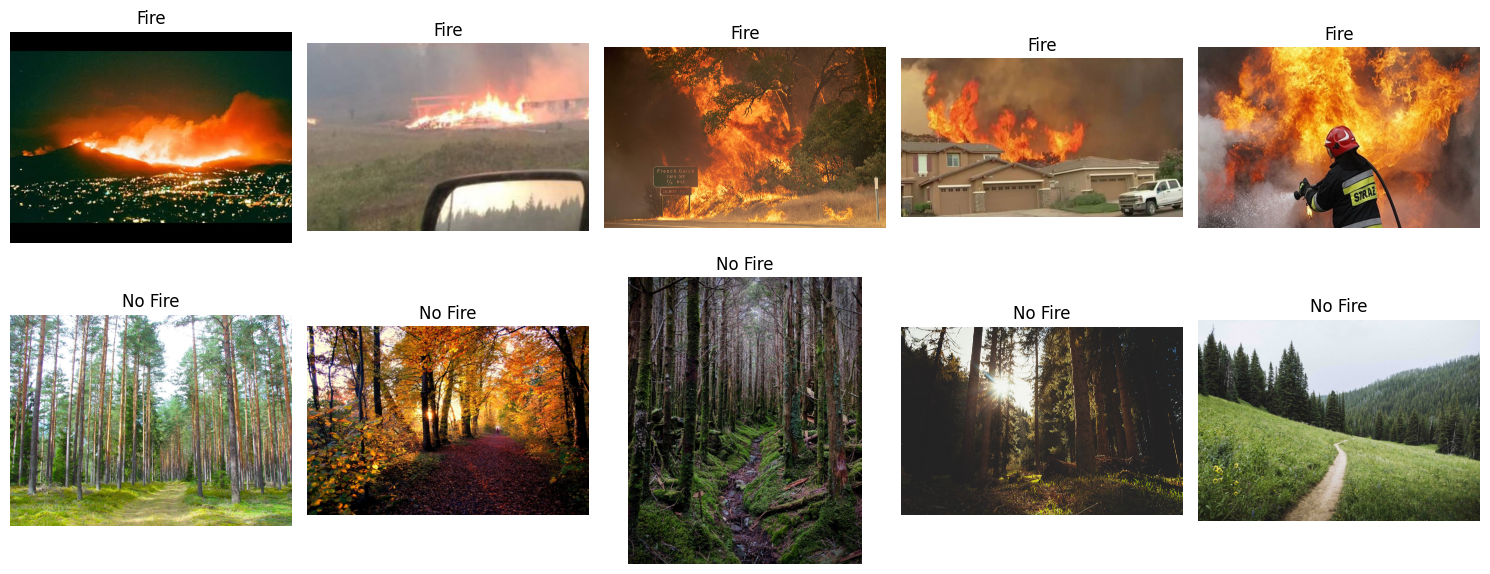

In [12]:
# Visualize a few sample images from each class
from PIL import Image
import numpy as np

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i in range(5):
    try:
        img_path = os.path.join(fire_dir, fire_files[i])
        with Image.open(img_path) as img_pil:
            img = np.array(img_pil)
        axes[0, i].imshow(img)
        axes[0, i].set_title("Fire")
        axes[0, i].axis('off')
    except Exception as e:
        print(f"Could not load fire image {fire_files[i]}: {e}")
        axes[0, i].set_title("Error")
        axes[0, i].axis('off') # Turn off axis for error image

for i in range(5):
    try:
        img_path = os.path.join(non_fire_dir, non_fire_files[i])
        with Image.open(img_path) as img_pil:
            img = np.array(img_pil)
        axes[1, i].imshow(img)
        axes[1, i].set_title("No Fire")
        axes[1, i].axis('off')
    except Exception as e:
        print(f"Could not load non-fire image {non_fire_files[i]}: {e}")
        axes[1, i].set_title("Error")
        axes[1, i].axis('off') # Turn off axis for error image

plt.tight_layout()
plt.show()

Image Size Summary

In [13]:
sizes = [Image.open(os.path.join(fire_dir, f)).size for f in fire_files] + \
        [Image.open(os.path.join(non_fire_dir, f)).size for f in non_fire_files]
widths, heights = zip(*sizes)
print(f"Width  - min: {min(widths)}, max: {max(widths)}, mean: {np.mean(widths):.0f}")
print(f"Height - min: {min(heights)}, max: {max(heights)}, mean: {np.mean(heights):.0f}")

Width  - min: 185, max: 6720, mean: 1153
Height - min: 147, max: 4608, mean: 738


**Image sizes:** The original images vary in width and height (see the summary above). A CNN needs a fixed input size, so every image will be resized in the next step.

## 4. Preprocessing

Preprocessing converts the raw image files into a clean numerical format that the CNN can learn from.

1. **Resizing to 128 × 128:** The images have different sizes, but a CNN needs a fixed input shape. 128 × 128 keeps enough detail (flames, smoke, colour) while keeping training fast and memory use low. Resizing to a square slightly changes the aspect ratio of some images.
2. **Normalisation (÷ 255):** Pixel values are scaled from 0–255 to 0–1. This makes training more stable and helps the optimiser converge faster.
3. **Labelling:** Fire images are labelled `1` and non-fire images `0`.
4. **Error handling:** Unreadable or corrupt files are skipped with a warning instead of stopping the pipeline.
5. **Sorted file order:** Files are read in sorted order so that the later train/test split is identical on every machine.

The result is an array `X` of shape (999, 128, 128, 3) and a label vector `y` of shape (999,).

In [14]:
IMG_SIZE = 128

def load_images(folder, label, img_size=IMG_SIZE):
    images, labels = [], []
    for fname in sorted(os.listdir(folder)):
        if not fname.lower().endswith(('.png', '.jpg', '.jpeg')):
            continue
        path = os.path.join(folder, fname)
        try:
            img = tf.keras.utils.load_img(path, target_size=(img_size, img_size))
            img_array = tf.keras.utils.img_to_array(img) / 255.0   # normalize 0-1
            images.append(img_array)
            labels.append(label)
        except Exception as e:
            print(f"Skipping corrupt file: {fname} ({e})")
    return images, labels

print("Loading fire images...")
fire_imgs, fire_labels = load_images(fire_dir, label=1)

print("Loading non-fire images...")
non_fire_imgs, non_fire_labels = load_images(non_fire_dir, label=0)

X = np.array(fire_imgs + non_fire_imgs, dtype=np.float32)
y = np.array(fire_labels + non_fire_labels, dtype=np.float32)

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

Loading fire images...
Loading non-fire images...
X shape: (999, 128, 128, 3)
y shape: (999,)


### 4.1 Train / Validation / Test Split

The data is split into **70% training, 15% validation and 15% test**:
- **Training set (699 images):** used to learn the model weights.
- **Validation set (150 images):** used during training to monitor performance, for early stopping and for choosing the best epoch.
- **Test set (150 images):** kept untouched until the final evaluation, to give an unbiased estimate of real-world performance.

The split is **stratified**, so each subset keeps the same fire / non-fire ratio (about 75% / 25%). Without this, a small subset such as the test set could by chance contain very few non-fire images and give misleading metrics. A fixed `random_state=42` makes the split reproducible.

In [15]:
# Split: 70% train, 15% val, 15% test  (stratified to preserve class balance)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

print(f"Train: {X_train.shape[0]} images  ({y_train.sum():.0f} fire / {(y_train==0).sum():.0f} non-fire)")
print(f"Val:   {X_val.shape[0]} images  ({y_val.sum():.0f} fire / {(y_val==0).sum():.0f} non-fire)")
print(f"Test:  {X_test.shape[0]} images  ({y_test.sum():.0f} fire / {(y_test==0).sum():.0f} non-fire)")

Train: 699 images  (528 fire / 171 non-fire)
Val:   150 images  (114 fire / 36 non-fire)
Test:  150 images  (113 fire / 37 non-fire)


## 5. Data Augmentation

With only 699 training images, a CNN can easily **overfit** (memorise the training images). Augmentation creates slightly modified versions of the training images on the fly, which acts as a regulariser and teaches the model to recognise fire under different conditions.

| Transformation | Setting | Reason |
|---|---|---|
| Horizontal flip | on | Fire can appear in any direction |
| Rotation | ±20° | Camera angle varies |
| Zoom | ±15% | Fire appears at different distances |
| Width / height shift | 10% | Fire is not always centred |

Vertical flips are deliberately **not** used, since fire does not appear upside down in real images.

**Important:** augmentation is applied **only to the training set**. The validation and test generators use the original images, so the evaluation reflects real, unmodified data and no augmented copy of a test image can leak into training. Pixel scaling was already done in preprocessing, so no rescaling is needed here.

In [16]:
train_datagen = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=20,
    zoom_range=0.15,
    width_shift_range=0.1,
    height_shift_range=0.1
)

# No augmentation for validation/test — only real, unmodified images are evaluated
val_datagen = ImageDataGenerator()
test_datagen = ImageDataGenerator()

BATCH_SIZE = 32

train_generator = train_datagen.flow(X_train, y_train, batch_size=BATCH_SIZE, shuffle=True)
val_generator = val_datagen.flow(X_val, y_val, batch_size=BATCH_SIZE, shuffle=False)
test_generator = test_datagen.flow(X_test, y_test, batch_size=BATCH_SIZE, shuffle=False)

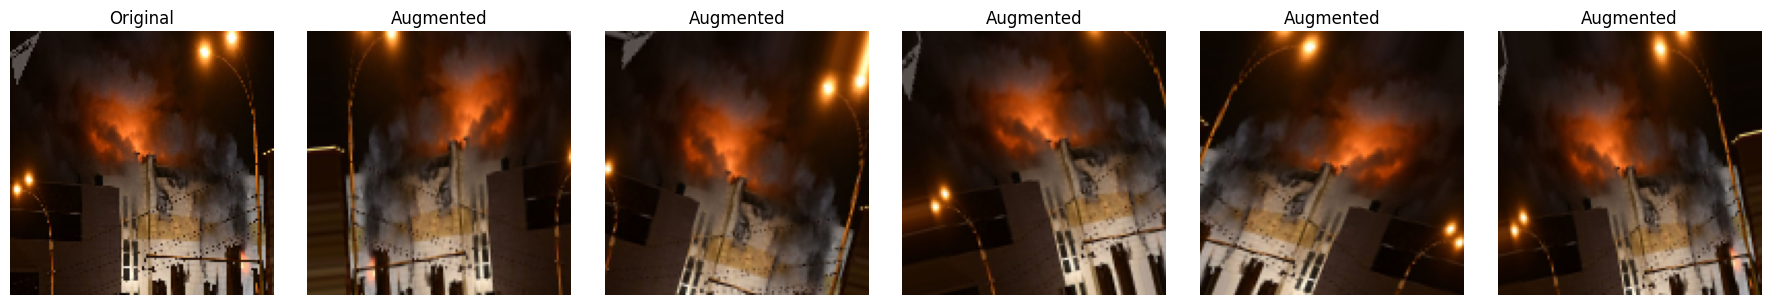

In [17]:
aug_iter = train_datagen.flow(X_train[:1], batch_size=1, seed=42)
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
axes[0].imshow(X_train[0]); axes[0].set_title('Original'); axes[0].axis('off')
for ax in axes[1:]:
    ax.imshow(np.clip(next(aug_iter)[0], 0, 1))
    ax.set_title('Augmented'); ax.axis('off')
plt.tight_layout(); plt.show()

The figure shows one training image (left) and five random augmented versions of it. The fire remains clearly visible, but its position, angle and scale vary.